# Tugas 3 – Implementasi Unsupervised Learning
## Segmentasi Pelanggan Berdasarkan Analisis Kepribadian Pelanggan

Notebook ini mengikuti urutan pada file `Tugas3b.ipynb`: eksplorasi, preprocessing, K-Means, evaluasi Elbow dan Silhouette, visualisasi PCA, serta profiling cluster.

In [ ]:
# 0. Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## Step 1: Load dataset
File `cpa.csv` menggunakan pemisah tab (`\\t`), meskipun ekstensi filenya `.csv`.

In [ ]:
df = pd.read_csv('cpa.csv', sep='\\t')
print('Ukuran data:', df.shape)
display(df.head())

Ukuran data: (2240, 29)


/tmp/ipykernel_1660/3128376188.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv('cpa.csv', sep='\\t')


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


## Step 2: Eksplorasi awal

Struktur dan tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurcha

,Missing Value
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Income,24
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0


\nStatistik deskriptif numerik:


,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


\nDistribusi fitur kategori:


,Jumlah
Education,
Graduation,1127
PhD,486
Master,370
2n Cycle,203
Basic,54


,Jumlah
Marital_Status,
Married,864
Together,580
Single,480
Divorced,232
Widow,77
Alone,3
Absurd,2
YOLO,2


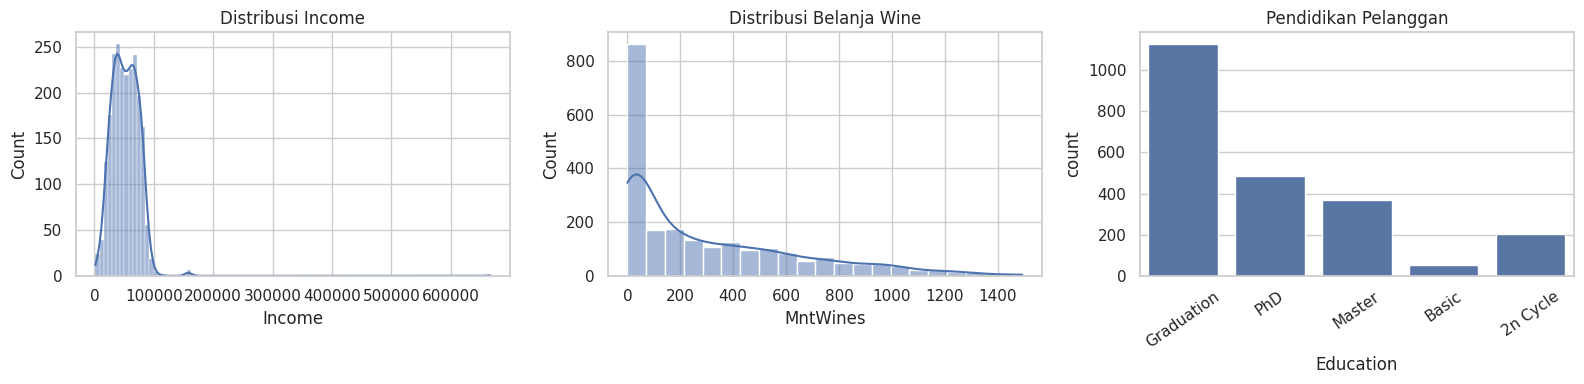

In [ ]:
print('Struktur dan tipe data:')
df.info()

print('\\nJumlah missing value per kolom:')
display(df.isna().sum().to_frame('Missing Value'))

print('\\nStatistik deskriptif numerik:')
display(df.describe().T)

print('\\nDistribusi fitur kategori:')
for col in ['Education', 'Marital_Status']:
    display(df[col].value_counts(dropna=False).to_frame('Jumlah'))

# Visualisasi beberapa fitur utama
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(df['Income'], kde=True, ax=axes[0])
axes[0].set_title('Distribusi Income')
sns.histplot(df['MntWines'], kde=True, ax=axes[1])
axes[1].set_title('Distribusi Belanja Wine')
sns.countplot(data=df, x='Education', ax=axes[2])
axes[2].set_title('Pendidikan Pelanggan')
axes[2].tick_params(axis='x', rotation=35)
plt.tight_layout()
plt.show()

## Step 3: Identifikasi kolom numerik dan kategori
Kolom ID tidak dipakai karena hanya identitas. Tanggal pendaftaran diubah menjadi lama menjadi pelanggan. Fitur umur dibuat dari tahun lahir dengan acuan tahun 2014 (periode data). Kolom biaya dan pendapatan kontak (`Z_CostContact`, `Z_Revenue`) tidak dipakai karena konstan.

In [ ]:
data = df.copy()
data['Dt_Customer'] = pd.to_datetime(data['Dt_Customer'], format='%d-%m-%Y', errors='coerce')
reference_date = data['Dt_Customer'].max()

data['Age'] = 2014 - data['Year_Birth']
# Nilai umur yang tidak masuk akal diperlakukan sebagai missing
data.loc[(data['Age'] < 18) | (data['Age'] > 100), 'Age'] = np.nan
data['Customer_Tenure_Days'] = (reference_date - data['Dt_Customer']).dt.days

# Fitur ringkasan perilaku pembelian
spending_cols = ['MntWines','MntFruits','MntMeatProducts',
                 'MntFishProducts','MntSweetProducts','MntGoldProds']
purchase_cols = ['NumWebPurchases','NumCatalogPurchases','NumStorePurchases']
data['Total_Spending'] = data[spending_cols].sum(axis=1)
data['Total_Purchases'] = data[purchase_cols].sum(axis=1)

cat_cols = ['Education', 'Marital_Status']
num_cols = ['Income','Age','Kidhome','Teenhome','Recency'] + spending_cols + [
    'NumDealsPurchases','NumWebPurchases','NumCatalogPurchases',
    'NumStorePurchases','NumWebVisitsMonth','AcceptedCmp1','AcceptedCmp2',
    'AcceptedCmp3','AcceptedCmp4','AcceptedCmp5','Complain',
    'Total_Spending','Total_Purchases','Customer_Tenure_Days'
]
print('Fitur numerik:', num_cols)
print('Fitur kategori:', cat_cols)
print('Jumlah missing Income:', data['Income'].isna().sum())
print('Jumlah umur tidak valid yang diubah menjadi missing:', data['Age'].isna().sum())

Fitur numerik: ['Income', 'Age', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Complain', 'Total_Spending', 'Total_Purchases', 'Customer_Tenure_Days']
Fitur kategori: ['Education', 'Marital_Status']
Jumlah missing Income: 24
Jumlah umur tidak valid yang diubah menjadi missing: 3


## Step 4: Imputasi missing value
Fitur numerik diimputasi menggunakan median. Fitur kategori diimputasi menggunakan modus. Nilai Income ekstrem dibatasi pada persentil ke-99 agar satu nilai sangat besar tidak mendominasi jarak K-Means; nilai asli tetap tersedia pada `df`.

In [ ]:
# Pembatasan outlier Income pada persentil ke-99 untuk proses clustering
data['Income'] = data['Income'].clip(upper=data['Income'].quantile(0.99))

numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

## Step 5: Encoding fitur kategori
One-Hot Encoding dipilih karena Education dan Marital_Status merupakan kategori nominal, bukan tingkatan angka yang memiliki jarak matematis.

In [ ]:
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, num_cols),
    ('cat', categorical_pipeline, cat_cols)
])

X = preprocessor.fit_transform(data[num_cols + cat_cols])
# Konversi ke array dense agar kompatibel dengan PCA dan evaluasi
if hasattr(X, 'toarray'):
    X = X.toarray()

print('Ukuran data setelah preprocessing:', X.shape)

Ukuran data setelah preprocessing: (2240, 38)


## Step 6: Scaling data
StandardScaler sudah diterapkan pada seluruh fitur numerik di dalam pipeline preprocessing agar skala fitur sebanding.

In [ ]:
print('Preprocessing selesai. Tidak ada missing value pada matriks hasil imputasi.')
print('Jumlah baris:', X.shape[0], '| Jumlah fitur setelah encoding:', X.shape[1])

Preprocessing selesai. Tidak ada missing value pada matriks hasil imputasi.
Jumlah baris: 2240 | Jumlah fitur setelah encoding: 38


## Step 7: Menentukan jumlah cluster optimal (Elbow + Silhouette)

,k,inertia,silhouette
0,2,44253.238831,0.267270
1,3,40289.389948,0.194116
2,4,37861.877230,0.191415
3,5,35870.351559,0.192762
4,6,35310.557236,0.107831
5,7,32341.748615,0.114352
6,8,31296.936152,0.112989


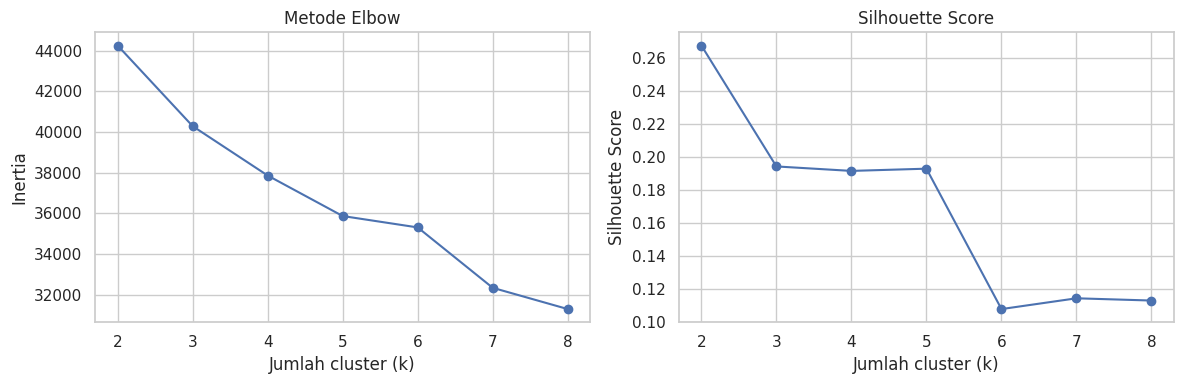

In [ ]:
results = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = model.fit_predict(X)
    results.append({
        'k': k,
        'inertia': model.inertia_,
        'silhouette': silhouette_score(X, labels)
    })

metrics = pd.DataFrame(results)
display(metrics)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(metrics['k'], metrics['inertia'], marker='o')
axes[0].set_title('Metode Elbow')
axes[0].set_xlabel('Jumlah cluster (k)')
axes[0].set_ylabel('Inertia')
axes[1].plot(metrics['k'], metrics['silhouette'], marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Jumlah cluster (k)')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

## Step 8: K-Means dan pemilihan k
Jumlah cluster dipilih berdasarkan Silhouette Score tertinggi pada rentang k=2 sampai k=8. Hasil evaluasi pada data ini menunjukkan k=2 memperoleh Silhouette Score tertinggi. Metode Elbow digunakan sebagai pemeriksaan tambahan.

In [ ]:
optimal_k = int(metrics.loc[metrics['silhouette'].idxmax(), 'k'])
kmeans = KMeans(n_clusters=optimal_k, random_state=RANDOM_STATE, n_init=10)
data['Cluster'] = kmeans.fit_predict(X)

print('Jumlah cluster terpilih:', optimal_k)
display(data['Cluster'].value_counts().sort_index().to_frame('Jumlah Pelanggan'))

Jumlah cluster terpilih: 2


,Jumlah Pelanggan
Cluster,
0,1307
1,933


## Step 9: Visualisasi cluster dengan PCA 2D

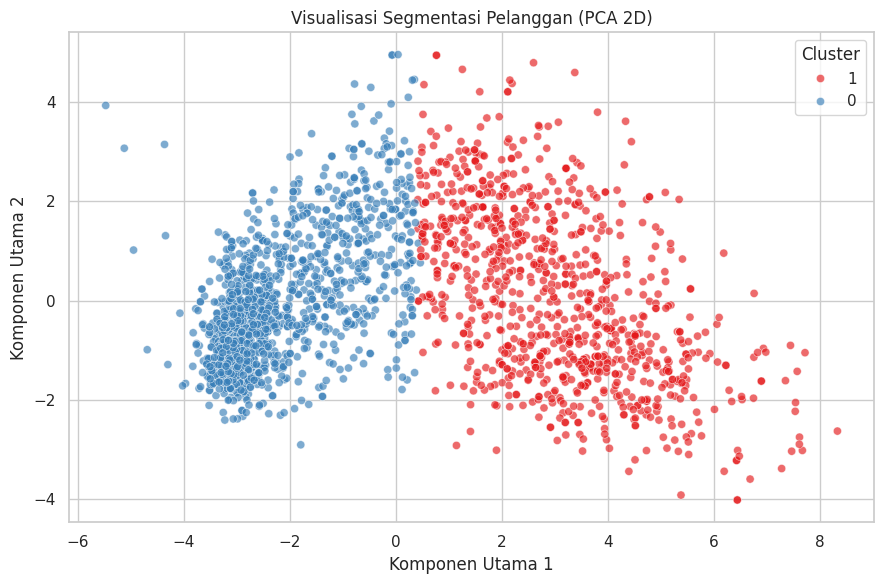

Variansi PCA yang dijelaskan: 40.09 %


In [ ]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
pca_df = pd.DataFrame({
    'PCA1': X_pca[:, 0],
    'PCA2': X_pca[:, 1],
    'Cluster': data['Cluster'].astype(str)
})

plt.figure(figsize=(9, 6))
sns.scatterplot(data=pca_df, x='PCA1', y='PCA2', hue='Cluster',
                palette='Set1', alpha=0.65, s=35)
plt.title('Visualisasi Segmentasi Pelanggan (PCA 2D)')
plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

print('Variansi PCA yang dijelaskan:', round(pca.explained_variance_ratio_.sum()*100, 2), '%')

## Step 10: Profiling cluster

In [ ]:
profile = data.groupby('Cluster')[num_cols].mean().round(2)
display(profile)

print('Kategori dominan pada setiap cluster:')
for cluster_id, group in data.groupby('Cluster'):
    print(f'Cluster {cluster_id}:')
    for col in cat_cols:
        print(f'  {col}: {group[col].mode().iloc[0]}')

# Perbandingan ukuran dan total belanja tiap cluster
cluster_summary = data.groupby('Cluster').agg(
    Jumlah_Pelanggan=('Cluster', 'size'),
    Rata_rata_Income=('Income', 'mean'),
    Rata_rata_Total_Spending=('Total_Spending', 'mean'),
    Rata_rata_Total_Purchases=('Total_Purchases', 'mean'),
    Rata_rata_Web_Visits=('NumWebVisitsMonth', 'mean')
).round(2)
display(cluster_summary)

,Income,Age,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,NumWebVisitsMonth,AcceptedCmp1,AcceptedCmp2,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,Complain,Total_Spending,Total_Purchases,Customer_Tenure_Days
Cluster,,,,,,,,,,,,,,,,,,,,,
0,38099.53,43.60,0.71,0.54,49.00,88.64,6.63,35.72,9.78,6.63,...,6.41,0.01,0.00,0.07,0.03,0.00,0.01,169.16,7.50,337.28
1,70815.79,47.19,0.08,0.45,49.27,605.53,53.86,350.78,76.40,55.69,...,3.78,0.15,0.03,0.08,0.14,0.17,0.01,1217.46,19.59,376.42


Kategori dominan pada setiap cluster:
Cluster 0:
  Education: Graduation
  Marital_Status: Married
Cluster 1:
  Education: Graduation
  Marital_Status: Married


,Jumlah_Pelanggan,Rata_rata_Income,Rata_rata_Total_Spending,Rata_rata_Total_Purchases,Rata_rata_Web_Visits
Cluster,,,,,
0,1307,38099.53,169.16,7.50,6.41
1,933,70815.79,1217.46,19.59,3.78


## Kesimpulan dan interpretasi

Berdasarkan evaluasi pada rentang k=2–8, jumlah cluster yang dipilih adalah **2**, karena menghasilkan Silhouette Score tertinggi. Hasil profiling pada data ini memperlihatkan dua kelompok utama:

- **Cluster 0 – pelanggan dengan belanja lebih rendah:** rata-rata income sekitar 38.100, total belanja sekitar 169, dan total transaksi sekitar 7,5. Kunjungan web per bulan relatif lebih tinggi (sekitar 6,4).
- **Cluster 1 – pelanggan dengan belanja lebih tinggi:** rata-rata income sekitar 70.816, total belanja sekitar 1.218, dan total transaksi sekitar 19,6. Kunjungan web per bulan lebih rendah (sekitar 3,8), sementara pembelian melalui katalog dan toko lebih tinggi.

Kedua kelompok memiliki rata-rata recency yang hampir sama (sekitar 49 hari), sehingga perbedaan utamanya lebih terlihat pada daya beli dan intensitas pembelian. Nama segmen tersebut merupakan interpretasi berdasarkan rata-rata fitur, bukan label yang sudah tersedia pada dataset.

**Catatan evaluasi:** Silhouette Score terbaik sekitar 0,267 (k=2), yang menunjukkan pemisahan cluster masih tergolong sedang/rendah dan terdapat kemungkinan tumpang tindih antar pelanggan. Segmentasi ini berguna sebagai gambaran awal, tetapi sebaiknya diuji kembali dengan pilihan fitur atau jumlah cluster lain sebelum dipakai untuk keputusan bisnis.

In [ ]:
# Simpan hasil segmentasi agar dapat digunakan kembali
data.to_csv('hasil_segmentasi_pelanggan.csv', index=False)
metrics.to_csv('evaluasi_jumlah_cluster.csv', index=False)
print('File hasil_segmentasi_pelanggan.csv dan evaluasi_jumlah_cluster.csv berhasil dibuat.')

File hasil_segmentasi_pelanggan.csv dan evaluasi_jumlah_cluster.csv berhasil dibuat.
